In [12]:
import uproot
import hist
import mplhep
mplhep.style.use("ROOT")
import matplotlib.pyplot as plt

In [32]:
# skip first event when all of the memory is being allocated and such
with uproot.open('performance-log.root') as f:
    s = f['performance/by_event'].arrays(entry_start=1)

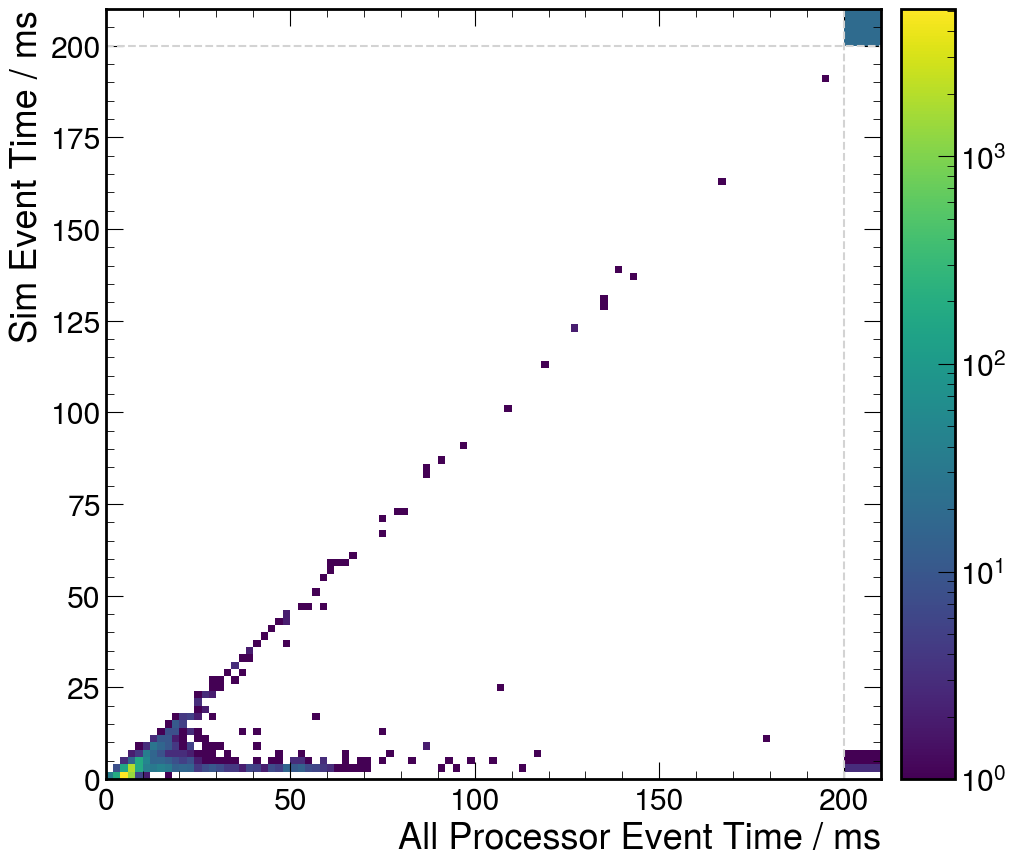

In [43]:
time_h = (
    hist.Hist.new
    .Reg(100,0,200, name="all", label='All Processor Event Time / ms')
    .Reg(100,0,200, name="sim", label='Sim Event Time / ms')
    .Double()
)
time_h.fill(
    sim = s["sim.duration_"]*1000,
    all = s["__ALL__.duration_"]*1000,
)
time_h.plot(norm='log', flow='show')
plt.show()

In [34]:
sim_frac_h = hist.Hist.new.Reg(100,0,1,label='Sim Time Fraction').Double()
sim_frac_h.fill(s["sim.duration_"]/s["__ALL__.duration_"])

Hist(Regular(100, 0, 1, label='Sim Time Fraction'), storage=Double()) # Sum: 9999.0

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f9de3b09f70>, errorbar=None, legend_artist=None)]

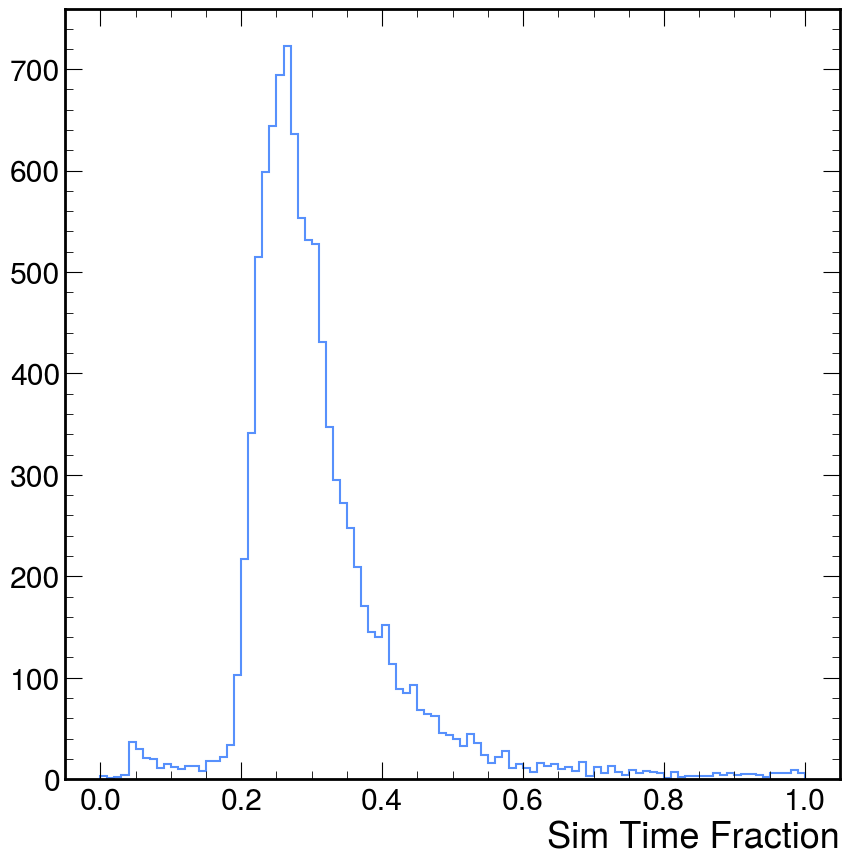

In [35]:
sim_frac_h.plot(yerr=False)